# ALP diphoton interpretation

Convert expected and observed diphoton signal limits into lower bounds on the ALP decay constant $f_a$.
The baseline uses $c_1=c_2=c_3=10$, up to one additional matrix-element jet with matching, and
NNPDF31_nnlo_as_0118_nf_4_mc_hessian (325500). Input provenance is recorded in `../data/README.md`.
Numerical consistency checks run alongside the calculation.

## From signal rates to the decay constant

For $c_1=c_2=c_3=10$, the diphoton signal rate falls as $1/f_a^2$: larger $f_a$ means a weaker signal. An upper limit on the signal rate therefore gives a **lower bound on $f_a$**, excluding smaller values.

We use the predicted cross section times diphoton branching fraction **after jet matching**, at $f_{a,0}=1$ TeV. With a $K=2$ correction to the leading-order prediction, the conversion is
$$
f_{a,\mathrm{limit}}=1\,\mathrm{TeV}\sqrt{\frac{2(\sigma\times\mathrm{BR})_{\mathrm{Theory}}}{(\sigma\times\mathrm{BR})_{\mathrm{CMS}}}}.
$$
The branching fraction is already included, and the factor two is applied once in this conversion. The theory plots below show the leading-order rates.

The expected bands describe the spread of limits expected without a signal. They do not include uncertainty in the theory prediction.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
import yaml
from IPython.display import display

# Locate the repository from its root or any directory beneath it.
BASE_DIR = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "interpretation" / "data").is_dir()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
DATA_DIR = BASE_DIR / "interpretation" / "data"
OUTPUT_DIR = BASE_DIR / "interpretation" / "results"
OUTPUT_DIR.mkdir(exist_ok=True)

K_FACTOR = 2.0
FA_REFERENCE_TEV = 1.0
plt.rcParams.update({"font.size": 12, "axes.linewidth": 1.2, "figure.dpi": 120})

## Expected and observed signal limits

The observed limit measures how large a diphoton signal is allowed by the data at each mass. The expected limit describes the sensitivity in the absence of a signal; its one- and two-standard-deviation bands show the range of possible outcomes from statistical fluctuations.

We check that masses are unique and ordered and that expected bands remain positive and correctly nested.

In [2]:
def read_limits(path, observed_name, expected_name, units):
    with path.open() as stream:
        table = yaml.safe_load(stream)
    independent = table["independent_variables"]
    if len(independent) != 1 or independent[0]["header"]["units"] != "GeV":
        raise ValueError("Expected one mass variable in GeV.")
    variables = {variable["header"]["name"]: variable for variable in table["dependent_variables"]}
    observed = variables[observed_name]
    expected = variables[expected_name]
    if any(variable["header"]["units"] != units for variable in (observed, expected)):
        raise ValueError(f"Expected limits in {units}.")
    masses = np.array([row["value"] for row in independent[0]["values"]], dtype=float)
    if not (len(masses) == len(observed["values"]) == len(expected["values"])):
        raise ValueError("Mass and limit arrays have different lengths.")
    frame = pd.DataFrame({
        "mass_GeV": masses,
        "observed": [row["value"] for row in observed["values"]],
        "expected": [row["value"] for row in expected["values"]],
    })
    for sigma in (1, 2):
        offsets = np.array([
            [
                next(error["asymerror"] for error in row["errors"] if error["label"] == f"{sigma}σ")[side]
                for side in ("minus", "plus")
            ]
            for row in expected["values"]
        ], dtype=float)
        if not (np.all(offsets.min(axis=1) <= 0) and np.all(offsets.max(axis=1) >= 0)):
            raise ValueError("Error offsets do not bracket the central value.")
        frame[f"expected_minus{sigma}sigma"] = frame["expected"] + offsets.min(axis=1)
        frame[f"expected_plus{sigma}sigma"] = frame["expected"] + offsets.max(axis=1)
    if not (np.isfinite(frame.to_numpy()).all() and (frame.to_numpy() > 0).all()):
        raise ValueError("Masses, limits, and band endpoints must be finite and positive.")
    if not np.all(np.diff(masses) > 0):
        raise ValueError("Masses must be unique and strictly increasing.")
    ordered = frame[[
        "expected_minus2sigma", "expected_minus1sigma", "expected",
        "expected_plus1sigma", "expected_plus2sigma",
    ]].to_numpy()
    if not np.all(np.diff(ordered, axis=1) >= 0):
        raise ValueError("Expected bands are not nested.")
    return frame


cms_limits = read_limits(DATA_DIR / "cross_section_limits_v1.yaml", "Obs limit", "Exp limit", "pb")
print(f"Loaded {len(cms_limits)} mass hypotheses from {cms_limits.mass_GeV.min():g} to {cms_limits.mass_GeV.max():g} GeV.")
display(cms_limits.head())

Loaded 130 mass hypotheses from 10 to 70 GeV.


,mass_GeV,observed,expected,expected_minus1sigma,expected_plus1sigma,expected_minus2sigma,expected_plus2sigma
0,10.0,2.9671,1.8828,1.23323,2.74587,0.90462,3.8515
1,10.2,2.5946,1.8047,1.23325,2.74589,0.90465,3.8516
2,10.4,2.6337,1.6641,1.19505,2.61041,0.85303,3.6332
3,10.5,2.3552,1.5859,1.08992,2.44009,0.79949,3.4124
4,10.7,1.0419,1.4062,1.05331,2.33816,0.77433,3.2795


## Predict the signal rate at each mass

The theory predictions are available every 5 GeV. We connect neighboring predictions with straight lines to obtain a signal rate at each mass tested by the search, keeping the measured limits at their original masses.

The plot shows how the predicted diphoton rate changes with ALP mass. The interpolation passes through every theory point and is used only within the available 10–70 GeV range.

Baseline: 1j after matching; NNPDF31_nnlo_as_0118_nf_4_mc_hessian (325500)


,mass_GeV,xsec_th_pb
0,10,20.10
1,15,19.00
2,20,17.70
3,25,16.10
4,30,14.40
5,35,13.10
6,40,11.90
7,45,10.80
8,50,9.92
9,55,9.09


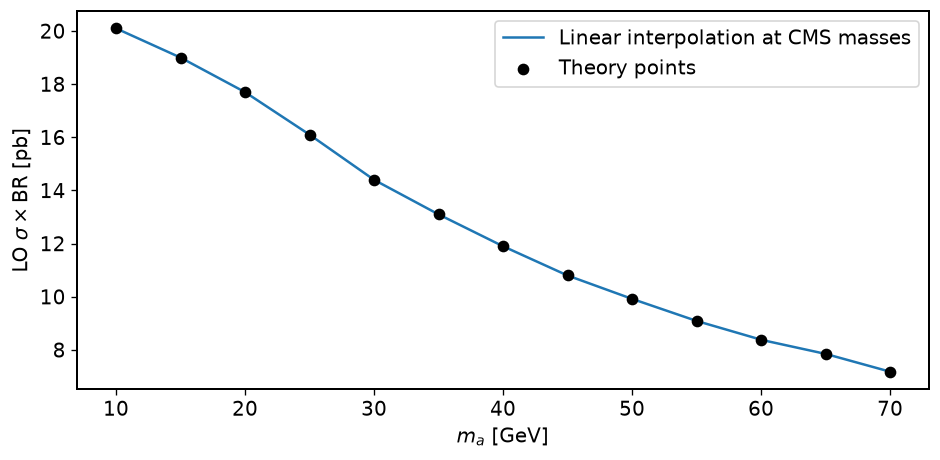

In [3]:
theory = pd.read_csv(DATA_DIR / "theory_baseline_1j_matched.csv")
with (DATA_DIR / "theory_baseline_1j_matched.json").open() as stream:
    theory_metadata = json.load(stream)
assert list(theory.mass_GeV) == list(range(10, 71, 5))
assert np.isfinite(theory.to_numpy()).all() and (theory.to_numpy() > 0).all()
np.testing.assert_allclose(theory.xsec_th_pb.iloc[[0, -1]], [20.1, 7.18])
assert theory_metadata["jet_matching"] == "after matching"
assert theory_metadata["pdf_id"] == 325500
assert theory_metadata["fa_reference_TeV"] == FA_REFERENCE_TEV
print(f"Baseline: 1j after matching; {theory_metadata['pdf_set']} ({theory_metadata['pdf_id']})")


def interpolate_theory(masses):
    masses = np.asarray(masses, dtype=float)
    if not np.isfinite(masses).all():
        raise ValueError("Masses must be finite.")
    if np.any((masses < theory.mass_GeV.min()) | (masses > theory.mass_GeV.max())):
        raise ValueError("Theory interpolation is restricted to 10–70 GeV.")
    return np.interp(masses, theory["mass_GeV"], theory["xsec_th_pb"])


mass = cms_limits["mass_GeV"].to_numpy()
theory_at_limits = interpolate_theory(mass)
np.testing.assert_allclose(interpolate_theory(theory.mass_GeV), theory.xsec_th_pb, rtol=0, atol=0)
np.testing.assert_allclose(interpolate_theory([12.5]), [19.55])
display(theory)

figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(mass, theory_at_limits, label="Linear interpolation at CMS masses")
axis.scatter(theory.mass_GeV.to_numpy(), theory.xsec_th_pb.to_numpy(), color="black", zorder=3, label="Theory points")
axis.set(xlabel=r"$m_a$ [GeV]", ylabel=r"LO $\sigma\times\mathrm{BR}$ [pb]")
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "theory_interpolation.pdf")
plt.show()

## Dependence on the decay constant

At fixed couplings, the diphoton rate scales as $1/f_a^2$. The curves use the same matched prediction
as the limit conversion. Internal checks cover the inverse-square rate law and a cubic mass-scaling fixture;
these are algebraic checks, not independent simulation validation.

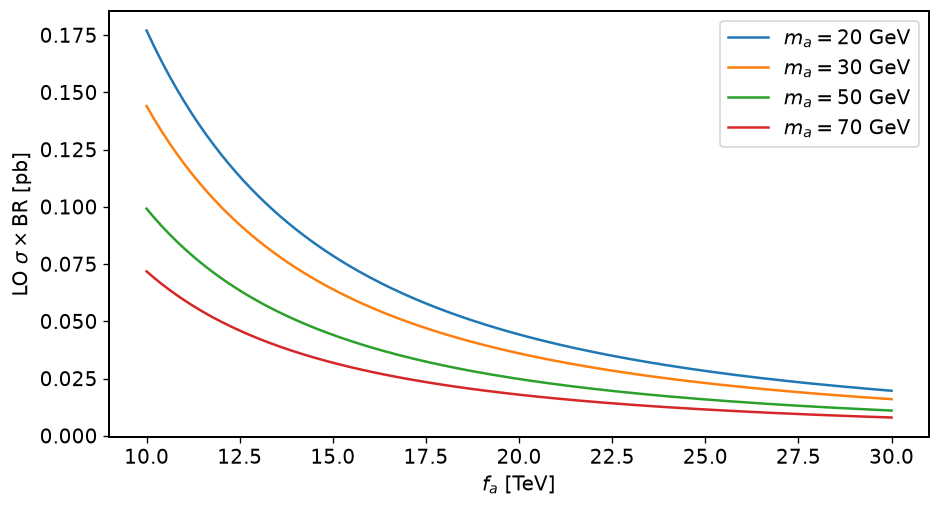

In [4]:
validation_masses = np.array([20.0, 30.0, 50.0, 70.0])
fa_scan_TeV = np.linspace(10, 30, 201)
selected_normalizations = interpolate_theory(validation_masses)
selected_cross_sections = selected_normalizations[:, None] * (FA_REFERENCE_TEV / fa_scan_TeV[None, :]) ** 2

# Internal scaling fixtures; the width normalization has arbitrary units.
validation_mass_scan = np.linspace(10, 70, 241)
validation_width = 3.13e-8 * validation_mass_scan ** 3
np.testing.assert_allclose(
    np.polyfit(np.log(validation_mass_scan), np.log(validation_width), 1)[0],
    3.0, atol=1e-12, rtol=0,
)
np.testing.assert_allclose(
    [np.polyfit(np.log(fa_scan_TeV), np.log(values), 1)[0] for values in selected_cross_sections],
    -2.0, atol=1e-12, rtol=0,
)
np.testing.assert_allclose(
    selected_cross_sections * (fa_scan_TeV[None, :] / FA_REFERENCE_TEV) ** 2,
    np.broadcast_to(selected_normalizations[:, None], selected_cross_sections.shape),
)

figure, axis = plt.subplots(figsize=(8, 4.4))
for mass_value, curve in zip(validation_masses, selected_cross_sections):
    axis.plot(fa_scan_TeV, curve, label=rf"$m_a={mass_value:g}$ GeV")
axis.set(xlabel=r"$f_a$ [TeV]", ylabel=r"LO $\sigma\times\mathrm{BR}$ [pb]")
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "fa_scaling.pdf")
plt.show()

## Calculate the decay-constant limits and expected bands

We convert the observed and expected signal limits into lower bounds on $f_a$ at each mass. A smaller allowed signal rate gives a stronger bound on $f_a$.

The same conversion is applied to both edges of each expected band. Since the conversion reverses the ordering, the upper edge of a cross-section band becomes the lower edge of the corresponding $f_a$ band. This preserves the full asymmetric shape of the expected bands.

In [5]:
def to_fa(cross_section_limit_pb, theory_pb):
    limits = np.asarray(cross_section_limit_pb, dtype=float)
    predictions = np.asarray(theory_pb, dtype=float)
    if not (np.isfinite(limits).all() and np.isfinite(predictions).all()):
        raise ValueError("Cross sections must be finite.")
    if np.any(limits <= 0) or np.any(predictions <= 0):
        raise ValueError("Cross sections must be positive.")
    return FA_REFERENCE_TEV * np.sqrt(K_FACTOR * predictions / limits)


results = pd.DataFrame({"mass_GeV": mass, "xsec_th_pb": theory_at_limits})
for column in cms_limits.columns:
    if column != "mass_GeV":
        results[f"xsec_{column}_pb"] = cms_limits[column].to_numpy()

for kind in ("observed", "expected"):
    results[f"fa_{kind}_TeV"] = to_fa(cms_limits[kind], theory_at_limits)
for sigma in (1, 2):
    results[f"fa_expected_minus{sigma}sigma_TeV"] = to_fa(
        cms_limits[f"expected_plus{sigma}sigma"], theory_at_limits
    )
    results[f"fa_expected_plus{sigma}sigma_TeV"] = to_fa(
        cms_limits[f"expected_minus{sigma}sigma"], theory_at_limits
    )
    results[f"fa_expected_err_minus{sigma}sigma_TeV"] = (
        results.fa_expected_TeV - results[f"fa_expected_minus{sigma}sigma_TeV"]
    )
    results[f"fa_expected_err_plus{sigma}sigma_TeV"] = (
        results[f"fa_expected_plus{sigma}sigma_TeV"] - results.fa_expected_TeV
    )

fa_band_columns = [
    "fa_expected_minus2sigma_TeV", "fa_expected_minus1sigma_TeV", "fa_expected_TeV",
    "fa_expected_plus1sigma_TeV", "fa_expected_plus2sigma_TeV",
]
assert np.all(np.diff(results[fa_band_columns].to_numpy(), axis=1) >= 0)
for kind in ("observed", "expected"):
    np.testing.assert_allclose(
        K_FACTOR * theory_at_limits / (results[f"fa_{kind}_TeV"] / FA_REFERENCE_TEV) ** 2,
        cms_limits[kind],
    )
for sigma in (1, 2):
    for fa_side, xsec_side in (("minus", "plus"), ("plus", "minus")):
        np.testing.assert_allclose(
            K_FACTOR * theory_at_limits / (results[f"fa_expected_{fa_side}{sigma}sigma_TeV"] / FA_REFERENCE_TEV) ** 2,
            cms_limits[f"expected_{xsec_side}{sigma}sigma"],
        )
print("Interpolation, endpoint ordering, and inverse-conversion checks passed.")
display(results[["mass_GeV", "xsec_th_pb", "fa_observed_TeV"] + fa_band_columns].head(10))

Interpolation, endpoint ordering, and inverse-conversion checks passed.


,mass_GeV,xsec_th_pb,fa_observed_TeV,fa_expected_minus2sigma_TeV,fa_expected_minus1sigma_TeV,fa_expected_TeV,fa_expected_plus1sigma_TeV,fa_expected_plus2sigma_TeV
0,10.0,20.100,3.680840,3.230711,3.826247,4.620734,5.709407,6.666224
1,10.2,20.056,3.931895,3.227131,3.822043,4.714489,5.703108,6.658814
2,10.4,20.012,3.898316,3.319064,3.915668,4.904227,5.787183,6.849803
3,10.5,19.990,4.120098,3.422878,4.047795,5.020922,6.056533,7.071554
4,10.7,19.946,6.187709,3.487700,4.130530,5.326223,6.154104,7.177610
5,10.9,19.902,6.485239,3.630385,4.334980,5.506983,6.371371,7.409082
6,11.1,19.858,5.466432,3.811670,4.555055,5.672243,6.569819,7.660533
7,11.3,19.814,5.027863,3.946001,4.698185,5.815081,6.773483,7.860745
8,11.5,19.770,5.749800,4.051520,4.816525,5.928462,6.932075,8.028722
9,11.7,19.726,7.955009,4.133007,4.917175,6.016738,7.048681,8.185463


## Excluded values of the decay constant

The curves show the lower bounds on $f_a$ as a function of ALP mass: values below the observed curve are excluded. The expected curve and its bands show the search sensitivity in the absence of a signal.

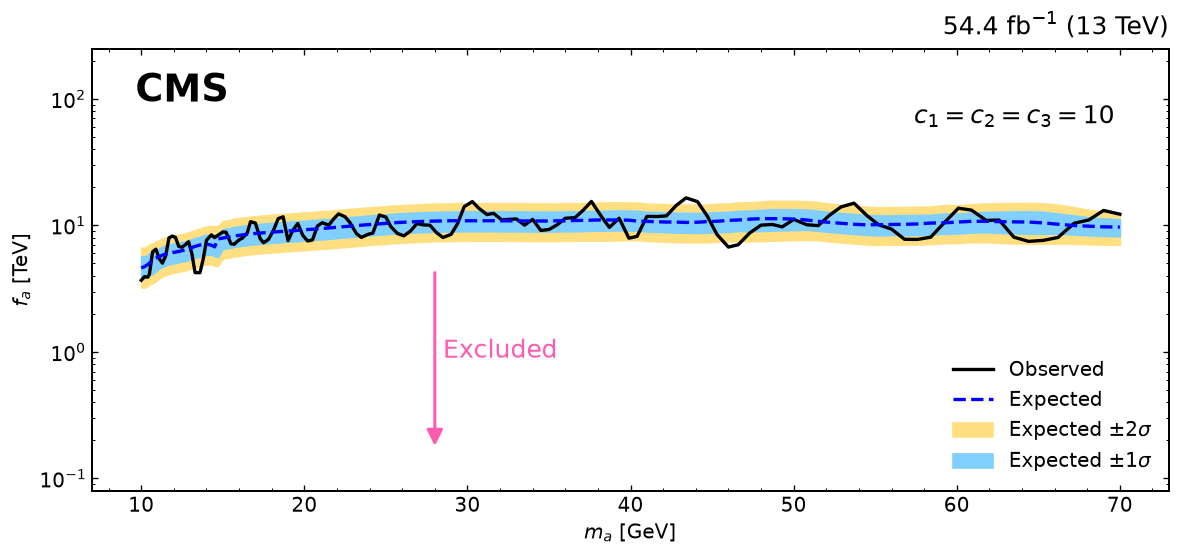

In [6]:
def plot_fa_limits(masses, frame):
    figure, axis = plt.subplots(figsize=(10, 4.8))
    band2 = axis.fill_between(
        masses, frame["expected_minus2sigma"].to_numpy(), frame["expected_plus2sigma"].to_numpy(),
        color="#ffdf80", label=r"Expected $\pm2\sigma$",
    )
    band1 = axis.fill_between(
        masses, frame["expected_minus1sigma"].to_numpy(), frame["expected_plus1sigma"].to_numpy(),
        color="#80cfff", label=r"Expected $\pm1\sigma$",
    )
    observed_line, = axis.plot(masses, frame["observed"].to_numpy(), color="black", linewidth=2, label="Observed")
    expected_line, = axis.plot(
        masses, frame["expected"].to_numpy(), color="blue", linestyle="--", linewidth=2, label="Expected",
    )
    axis.set(
        xlim=(7, 73), ylim=(0.08, 250), yscale="log",
        xlabel=r"$m_a$ [GeV]", ylabel=r"$f_a$ [TeV]",
    )
    axis.text(0.04, 0.88, "CMS", transform=axis.transAxes, fontsize=23, fontweight="bold")
    axis.text(1, 1.03, r"54.4 fb$^{-1}$ (13 TeV)", transform=axis.transAxes, ha="right", fontsize=15)
    axis.text(0.95, 0.83, r"$c_1=c_2=c_3=10$", transform=axis.transAxes, ha="right", fontsize=15)
    axis.annotate("", xy=(28, 0.17), xytext=(28, 4.5),
                  arrowprops={"arrowstyle": "-|>", "color": "#ff5bb0", "lw": 1.8, "mutation_scale": 20})
    axis.text(28.5, 0.9, "Excluded", color="#ff5bb0", fontsize=15)
    axis.legend(handles=[observed_line, expected_line, band2, band1], loc="lower right", frameon=False)
    axis.xaxis.set_minor_locator(AutoMinorLocator(5))
    axis.tick_params(which="both", direction="in", top=True, right=True)
    figure.tight_layout()
    return figure, axis


computed_fa = pd.DataFrame({"mass_GeV": mass})
for column in cms_limits.columns:
    if column != "mass_GeV":
        computed_fa[column] = results[f"fa_{column}_TeV"].to_numpy()

figure, axis = plot_fa_limits(mass, computed_fa)
figure.savefig(OUTPUT_DIR / "fa_limits.pdf")
figure.savefig(OUTPUT_DIR / "fa_limits.png", dpi=180)
plt.show()

## Save the results

Save the observed and expected $f_a$ bounds, their expected bands, and the signal rates at every tested mass.
Cross sections are in pb and decay constants are in TeV. Band endpoints and distances from the expected
central value are stored separately. Results are written to `interpretation/results/`.

In [7]:
results.to_csv(OUTPUT_DIR / "fa_limits_baseline_1j_matched.csv", index=False, float_format="%.10g")
theory.to_csv(OUTPUT_DIR / "reference_theory_baseline_1j_matched.csv", index=False)
print(f"Saved all {len(results)} mass points and plots to {OUTPUT_DIR.resolve()}")
display(results)
with (OUTPUT_DIR / "theory_baseline_metadata.json").open("w") as stream:
    json.dump(theory_metadata, stream, indent=2)

Saved all 130 mass points and plots to /Users/Elisa_1/Desktop/WORK/LowMassDiPhoton-Search/interpretation/results


,mass_GeV,xsec_th_pb,xsec_observed_pb,xsec_expected_pb,xsec_expected_minus1sigma_pb,xsec_expected_plus1sigma_pb,xsec_expected_minus2sigma_pb,xsec_expected_plus2sigma_pb,fa_observed_TeV,fa_expected_TeV,fa_expected_minus1sigma_TeV,fa_expected_plus1sigma_TeV,fa_expected_err_minus1sigma_TeV,fa_expected_err_plus1sigma_TeV,fa_expected_minus2sigma_TeV,fa_expected_plus2sigma_TeV,fa_expected_err_minus2sigma_TeV,fa_expected_err_plus2sigma_TeV
0,10.0,20.1000,2.967100,1.88280,1.233230,2.745870,0.904620,3.85150,3.680840,4.620734,3.826247,5.709407,0.794486,1.088673,3.230711,6.666224,1.390023,2.045491
1,10.2,20.0560,2.594600,1.80470,1.233250,2.745890,0.904650,3.85160,3.931895,4.714489,3.822043,5.703108,0.892446,0.988619,3.227131,6.658814,1.487358,1.944324
2,10.4,20.0120,2.633700,1.66410,1.195050,2.610410,0.853030,3.63320,3.898316,4.904227,3.915668,5.787183,0.988558,0.882956,3.319064,6.849803,1.585163,1.945577
3,10.5,19.9900,2.355200,1.58590,1.089920,2.440090,0.799490,3.41240,4.120098,5.020922,4.047795,6.056533,0.973128,1.035611,3.422878,7.071554,1.598044,2.050632
4,10.7,19.9460,1.041900,1.40620,1.053310,2.338160,0.774330,3.27950,6.187709,5.326223,4.130530,6.154104,1.195693,0.827880,3.487700,7.177610,1.838523,1.851387
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,66.2,7.6892,0.239050,0.14746,0.099814,0.207366,0.072402,0.29837,8.020680,10.212180,8.611659,12.412517,1.600521,2.200337,7.179232,14.574051,3.032948,4.361871
126,67.2,7.5552,0.139850,0.15186,0.105345,0.210359,0.078343,0.29312,10.394575,9.975078,8.475346,11.976530,1.499732,2.001453,7.179848,13.887942,2.795230,3.912864
127,68.1,7.4346,0.121900,0.15332,0.111009,0.213596,0.084825,0.29503,11.044395,9.847917,8.343480,11.573500,1.504437,1.725582,7.099221,13.239813,2.748696,3.391896
128,69.0,7.3140,0.084986,0.15430,0.113543,0.213826,0.088043,0.29369,13.119545,9.736649,8.271080,11.350429,1.465569,1.613780,7.057451,12.889767,2.679198,3.153118
